# TP Fourier : Redimensionnement d'une image

On compare quatre méthodes de redimensionnement de l'image Barbara. Chaque méthode part de l'image originale.

Les trois canaux sont identiques, donc on en conserve un seul. Les flottants permettent de garder les valeurs non entières. La division par 255 ramène les pixels entre 0 et 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open("data/barbara.jpg")
img = np.array(img, dtype=float)
assert np.array_equal(img[:, :, 0], img[:, :, 1])
assert np.array_equal(img[:, :, 0], img[:, :, 2])
img = img[:, :, 0] / 255
height, width = img.shape

## 1. Analyse spectrale

On note $u$ l'image, $H$ sa hauteur et $W$ sa largeur. Avec la convention du cours :

$$F[k,\ell]=\sum_{m=0}^{H-1}\sum_{n=0}^{W-1}u[m,n]e^{-2i\pi(km/H+\ell n/W)}$$

L'inversion repose sur l'orthogonalité :

$$\frac1H\sum_{k=0}^{H-1}e^{2i\pi k(m-r)/H}
=\begin{cases}1&\text{si }m=r\pmod H,\\0&\text{sinon}\end{cases}$$

Dans le premier cas, chaque terme vaut 1. Sinon, la somme géométrique vaut $(1-z^H)/(1-z)=0$, avec $z=e^{2i\pi(m-r)/H}\ne1$.

En remplaçant $F$ par sa définition, cette identité élimine tous les termes sauf $u[m,n]$. On l'applique sur les deux axes :

$$u[m,n]=\frac1{HW}\sum_{k=0}^{H-1}\sum_{\ell=0}^{W-1}F[k,\ell]e^{2i\pi(km/H+\ell n/W)}$$

Ajouter $H$ à $m$, ou $W$ à $n$, ne change aucune exponentielle. La reconstruction est donc périodique sur les deux axes.

La fréquence horizontale d'indice $\ell$ vaut $\ell/W$ cycle par pixel. Deux fréquences séparées d'un entier coïncident aux pixels entiers. `fftshift` les range dans $[-1/2,1/2[$. Les bornes du graphique dépassent les fréquences extrêmes d'un demi-pas pour centrer les coefficients.

On affiche $g(a)=\log(1+a)$, avec $a=|F|$. Cette fonction est définie en zéro. Sa dérivée $g'(a)=1/(1+a)$ est positive et décroissante : elle conserve l'ordre des amplitudes et comprime les grands écarts.

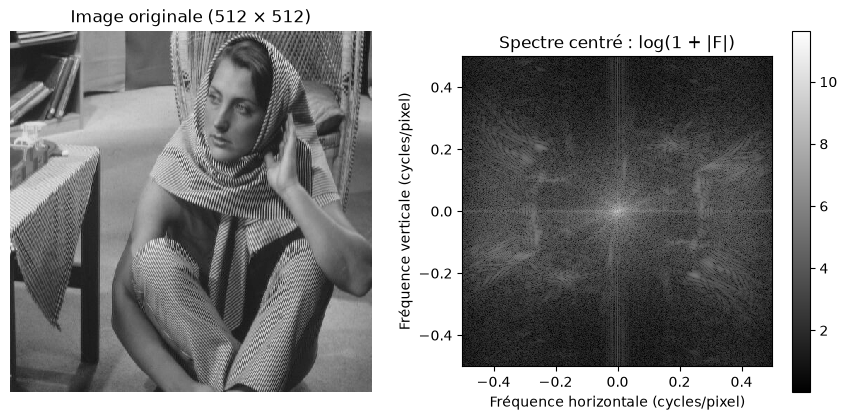

In [2]:
fft_img = np.fft.fft2(img)
fft_center = np.fft.fftshift(fft_img)
log_spec = np.log1p(np.abs(fft_center))

freq_x = np.fft.fftshift(np.fft.fftfreq(width))
freq_y = np.fft.fftshift(np.fft.fftfreq(height))
bounds = [freq_x[0] - 1 / (2 * width), freq_x[-1] + 1 / (2 * width), freq_y[0] - 1 / (2 * height), freq_y[-1] + 1 / (2 * height)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.7))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[0].set_title("Image originale (512 × 512)")
axes[0].axis("off")

spec_plot = axes[1].imshow(log_spec, cmap="gray", origin="lower", extent=bounds, interpolation="nearest")
axes[1].set_title("Spectre centré : log(1 + |F|)")
axes[1].set_xlabel("Fréquence horizontale (cycles/pixel)")
axes[1].set_ylabel("Fréquence verticale (cycles/pixel)")
fig.colorbar(spec_plot, ax=axes[1])
plt.show()

Le centre est le point le plus lumineux. À la fréquence nulle :

$$F[0,0]=\sum_{m,n}u[m,n]=HW\,\mathrm{moyenne}(u)$$

Les pixels sont positifs. L'inégalité triangulaire justifie ce maximum :

$$|F[k,\ell]|\leq\sum_{m,n}|u[m,n]|=F[0,0]$$

La symétrie des taches vient du fait que $u$ est réelle :

$$\overline{F[k,\ell]}=\sum_{m,n}u[m,n]e^{2i\pi(km/H+\ell n/W)}=F[-k,-\ell]$$

Les modules sont donc égaux, avec des indices pris modulo $H$ et $W$.

On conserve cette symétrie lors du redimensionnement. Les termes opposés donnent $z+\overline z=2\operatorname{Re}(z)$, donc un résultat réel. Avant de prendre la partie réelle, le code contrôle le résidu imaginaire. La tolérance $10^{-12}$ est très inférieure au pas initial de gris, $1/255$.

## 2. Réduction par deux

### Sous-échantillonnage spatial

On garde un pixel sur deux sur chaque axe, sans filtrage :

$$u_s[p,q]=u[2p,2q]$$

Les dimensions passent de $512\times512$ à $256\times256$.

In [3]:
img_sub = img[::2, ::2]

### Réduction dans le domaine de Fourier

Après un prélèvement tous les deux pixels, deux fréquences séparées de $1/2$ deviennent indiscernables :

$$e^{2i\pi(\nu+1/2)(2p)}=e^{2i\pi\nu(2p)}e^{2i\pi p}=e^{2i\pi\nu(2p)}$$

On garde donc la bande centrée $[-1/4,1/4]$ sur chaque axe, en cycles par pixel d'origine. Les autres coefficients sont annulés pour éviter leur repliement. On note $u_{\mathrm{bas}}$ l'image ainsi filtrée. Le résultat recherché est $u_{\mathrm{bas}}[2p,2q]$

Les indices conservés vont de $-H/4$ à $H/4$ sur les lignes. Dans la FFT non centrée, les indices positifs suivent zéro et les indices négatifs terminent le tableau. Cela explique les deux tranches réunies par "np.concatenate".

Les coefficients aux deux bornes sont additionnés, car :

$$e^{2i\pi(\pm H/4)(2p)/H}=e^{\pm i\pi p}=(-1)^p$$

On fait de même sur les colonnes. Les additions successives regroupent aussi les quatre coefficients des coins et conservent les paires conjuguées.

La phase correspond alors à une inverse de taille $(H/2)\times(W/2)$. Son facteur vaut :

$$\frac1{(H/2)(W/2)}=\frac4{HW}$$

On divise donc le résultat par 4. Le coefficient nul étant conservé, la moyenne reste $F[0,0]/(HW)$.

In [ ]:
def shrink_fft(img):
    height, width = img.shape
    fft_img = np.fft.fft2(img)
    row_cut, col_cut = height // 4, width // 4

    fft_rows = np.concatenate((fft_img[:row_cut, :], fft_img[-row_cut:, :]), axis=0)
    fft_rows[row_cut, :] += fft_img[row_cut, :]

    fft_small = np.concatenate((fft_rows[:, :col_cut], fft_rows[:, -col_cut:]), axis=1)
    fft_small[:, col_cut] += fft_rows[:, col_cut]

    res = np.fft.ifft2(fft_small) / 4
    assert np.max(np.abs(res.imag)) < 1e-12
    return res.real

img_small = shrink_fft(img)
assert abs(img_small.mean() - img.mean()) < 1e-12

## 3. Agrandissement par deux

### Ajout de zéros dans le spectre

On double la taille du spectre sur chaque axe. On conserve les indices de fréquence et on complète par des zéros hors de la bande initiale.

À Nyquist, les indices $+N/2$ et $-N/2$ donnent tous deux $(-1)^m$ aux positions entières. On partage le coefficient par moitié :

$$\frac{e^{i\pi t}+e^{-i\pi t}}2=\cos(\pi t)$$

Cette expression est réelle et retrouve $(-1)^m$ aux entiers. Une composante en $\sin(\pi t)$ serait invisible aux échantillons initiaux. On choisit son coefficient nul. Sur les deux axes, le partage conserve la symétrie hermitienne ; aux coins, chaque part vaut un quart du coefficient.

Après ce partage, les coefficients $C[k,\ell]$ définissent l'interpolant :

$$P(t,s)=\frac1{HW}\sum_{k=-H/2}^{H/2}\sum_{\ell=-W/2}^{W/2}
C[k,\ell]e^{2i\pi(kt/H+\ell s/W)}$$

Aux entiers, les parts de Nyquist se recombinent. La formule inverse donne $P(m,n)=u[m,n]$

Sur la grille agrandie, on évalue $P(p/2,q/2)$ :

$$e^{2i\pi(k(p/2)/H+\ell(q/2)/W)}=e^{2i\pi(kp/(2H)+\ell q/(2W))}$$

C'est la phase d'une inverse de taille $2H\times2W$. Son facteur vaut $1/(4HW)$, donc on multiplie le résultat par 4. On retrouve alors les pixels initiaux : $u_{\mathrm{grand}}[2m,2n]=u[m,n]$

In [ ]:
def enlarge_fft(img):
    height, width = img.shape
    fft_img = np.fft.fft2(img)
    row_mid, col_mid = height // 2, width // 2

    fft_rows = np.zeros((2 * height, width), dtype=complex)
    fft_rows[:row_mid, :] = fft_img[:row_mid, :]
    fft_rows[-row_mid + 1:, :] = fft_img[row_mid + 1:, :]
    fft_rows[row_mid, :] = fft_img[row_mid, :] / 2
    fft_rows[-row_mid, :] = fft_img[row_mid, :] / 2

    fft_large = np.zeros((2 * height, 2 * width), dtype=complex)
    fft_large[:, :col_mid] = fft_rows[:, :col_mid]
    fft_large[:, -col_mid + 1:] = fft_rows[:, col_mid + 1:]
    fft_large[:, col_mid] = fft_rows[:, col_mid] / 2
    fft_large[:, -col_mid] = fft_rows[:, col_mid] / 2

    res = 4 * np.fft.ifft2(fft_large)
    assert np.max(np.abs(res.imag)) < 1e-12
    return res.real

img_large = enlarge_fft(img)
assert np.allclose(img_large[::2, ::2], img, rtol=0, atol=1e-12)

### Lien avec l'interpolation par sinus cardinal

Sur un axe de taille paire $N$, on remplace les coefficients par leur définition. En regroupant les fréquences opposées :

$$P_N(t)=\sum_{m=0}^{N-1}x[m]K_N(t-m),$$

$$K_N(t)=\frac1N\left[1+2\sum_{k=1}^{N/2-1}\cos\left(\frac{2\pi kt}{N}\right)+\cos(\pi t)\right]$$

Le dernier terme vient du partage de Nyquist. Avec $\theta=2\pi t/N$, l'identité

$$2\sin(\theta/2)\cos(k\theta)=\sin((k+1/2)\theta)-\sin((k-1/2)\theta)$$

fait apparaître une somme télescopique :

$$N K_N(t)\sin(\theta/2)=\sin(N\theta/2)\cos(\theta/2)$$

D'où, avec prolongement par continuité si nécessaire :

$$K_N(t)=\frac{\sin(\pi t)}{N\tan(\pi t/N)}$$

La somme de cosinus est périodique de période $N$. Aux entiers, l'orthogonalité donne $K_N(r)=1$ si $r=0\pmod N$, et 0 sinon. Ce noyau interpole donc les échantillons.

À $t$ fixé, $N\tan(\pi t/N)\to\pi t$, donc :

$$K_N(t)\longrightarrow\frac{\sin(\pi t)}{\pi t}=\operatorname{sinc}(t)$$

Pour l'image finie, on utilise ce noyau périodique sur les deux axes. Leur séparation dans la DFT donne le produit $K_H(t-m)K_W(s-n)$.

### Interpolation bilinéaire

Le pixel $(p,q)$ correspond encore au point $(p/2,q/2)$ de l'image d'origine.

Entre $a$ et $b$, on cherche une fonction affine $L(t)=\alpha+\beta t$. Les conditions $L(0)=a$ et $L(1)=b$ donnent :

$$L(t)=(1-t)a+tb$$

En appliquant cette interpolation sur les deux axes :

$$B(s,t)=(1-s)(1-t)a+(1-s)tb+s(1-t)c+st d,$$

où $a,b$ sont les pixels du haut et $c,d$ ceux du bas. À mi-distance sur un axe, les poids valent $1/2$. Au centre des quatre pixels, ils valent $1/4$. Aux positions initiales, un seul poids vaut 1.

"np.roll" relie les derniers pixels aux premiers. On conserve ainsi les mêmes bords périodiques que pour Fourier.

In [6]:
right = np.roll(img, -1, axis=1)
below = np.roll(img, -1, axis=0)
diag = np.roll(below, -1, axis=1)

img_linear = np.zeros((2 * height, 2 * width))
img_linear[::2, ::2] = img
img_linear[::2, 1::2] = (img + right) / 2
img_linear[1::2, ::2] = (img + below) / 2
img_linear[1::2, 1::2] = (img + right + below + diag) / 4

## 4. Comparaison des résultats

On compare les images entières et un même détail à rayures. Les coordonnées du détail sont adaptées à chaque résolution.

L'échelle de gris est commune : une même valeur reçoit le même gris. Ses bornes couvrent tous les résultats, sans écrêtage. "interpolation="nearest" évite d'ajouter un lissage lors de l'affichage.

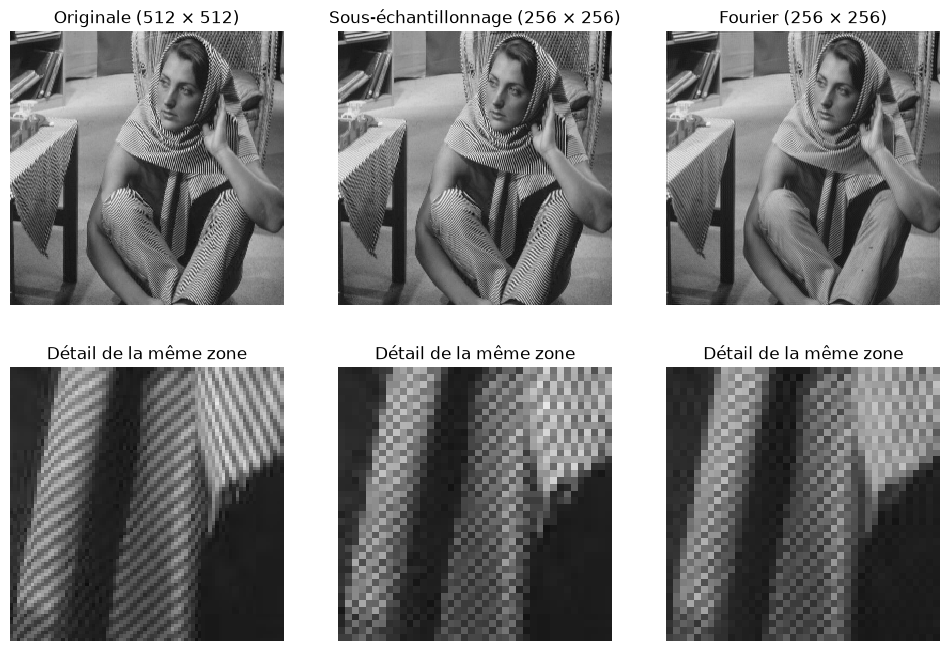

In [ ]:
results = [img, img_sub, img_small, img_large, img_linear]
vmin = min(res.min() for res in results)
vmax = max(res.max() for res in results)

def compare_imgs(imgs, crops, titles):
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for idx in range(3):
        axes[0, idx].imshow(imgs[idx], cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
        axes[0, idx].set_title(titles[idx])
        axes[1, idx].imshow(crops[idx], cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
        axes[1, idx].set_title("Détail de la même zone")
        axes[0, idx].axis("off")
        axes[1, idx].axis("off")
    plt.show()

imgs = [img, img_sub, img_small]
crops = [img[280:360, 280:360], img_sub[140:180, 140:180], img_small[140:180, 140:180]]
titles = ["Originale (512 × 512)", "Sous-échantillonnage (256 × 256)", "Fourier (256 × 256)"]
compare_imgs(imgs, crops, titles)

**Réduction.** Le prélèvement direct produit des ondulations plus larges et des motifs en damier. Ces observations sont cohérentes avec le repliement démontré plus haut.

Avec Fourier, les faux motifs et les rayures fines sont atténués. Le filtrage supprime les hautes fréquences : il limite leur repliement, mais perd les détails qu'elles représentaient.

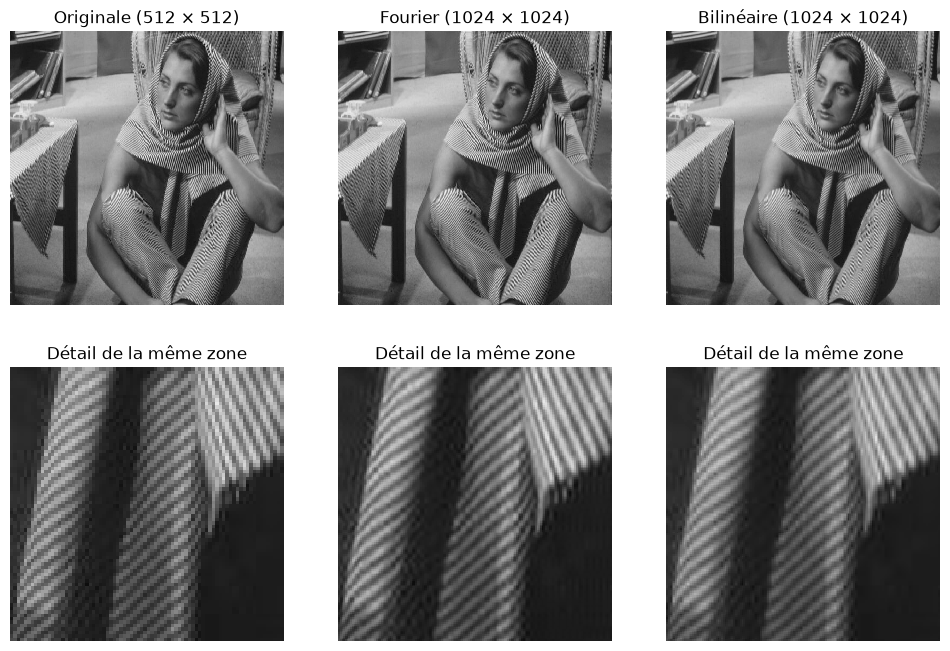

In [8]:
imgs = [img, img_large, img_linear]
crops = [img[280:360, 280:360], img_large[560:720, 560:720], img_linear[560:720, 560:720]]
titles = ["Originale (512 × 512)", "Fourier (1024 × 1024)", "Bilinéaire (1024 × 1024)"]
compare_imgs(imgs, crops, titles)

**Agrandissement.** Dans le détail, Fourier conserve des rayures plus contrastées. L'interpolation bilinéaire les adoucit.

La moyenne de deux valeurs d'une sinusoïde complexe s'écrit :

$$\frac{e^{2i\pi\nu n}+e^{2i\pi\nu(n+1)}}2
=e^{2i\pi\nu(n+1/2)}\cos(\pi\nu)$$

Au point intermédiaire, l'amplitude est donc multipliée par $|\cos(\pi\nu)|$. Ce facteur décroît de 1 à 0 lorsque $|\nu|$ va de 0 à $1/2$. Les variations rapides sont plus atténuées. Aux centres des quatre pixels, les facteurs des deux axes se multiplient.

Cette atténuation concerne les pixels ajoutés. Les deux méthodes retrouvent les pixels initiaux, à l'arrondi près pour Fourier.

Les résultats dépendent uniquement de l'image de départ. L'agrandissement ne fournit donc aucune information nouvelle sur la scène.